# Titanic passenger EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
# Colab me train.csv upload karo (titanic.zip ke andar hai)
import os
if not os.path.exists('train.csv'):
    try:
        from google.colab import files
        uploaded = files.upload()   # train.csv select karo
    except ImportError:
        raise FileNotFoundError('train.csv notebook ke folder me rakho')

path = 'train.csv'
print('Path to dataset file:', path)


Path to dataset file: train.csv


## 2. Creating a Dataset

In [23]:
data = pd.read_csv('train.csv')

In [24]:
df = pd.DataFrame(data)

#QUESTION 1.COUNT SURVIVORS AND NON SURVIVORS

In [25]:
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [6]:
df.tail(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


#QUESTION 2. COUNT PASSENGERS BY SEX AND PASSENGER CLASS

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


#QUESTION 3 . CALCULATE AVERAGE AGE AND FARE

In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


#QUESTION 4 .COMPARE SURVIVAL COUNTS Y SEX AND PASSENGER CLASS

In [9]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


#QUESTION 5 . FIND MISSING VALUES IN AGE


In [10]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Cabin'] = df['Cabin'].fillna('Unknown')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    object 
 11  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [12]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [17]:
print('Overall survival rate: %.1f%%' % (df['Survived'].mean()*100))
(df.groupby('Sex')['Survived'].mean()*100).round(1)

Overall survival rate: 38.4%


,Survived
Sex,
female,74.2
male,18.9


In [18]:
(df.groupby('Pclass')['Survived'].mean()*100).round(1)

,Survived
Pclass,
1,63.0
2,47.3
3,24.2


QUESTION6.LIST THE 10 HIGHEST FARES

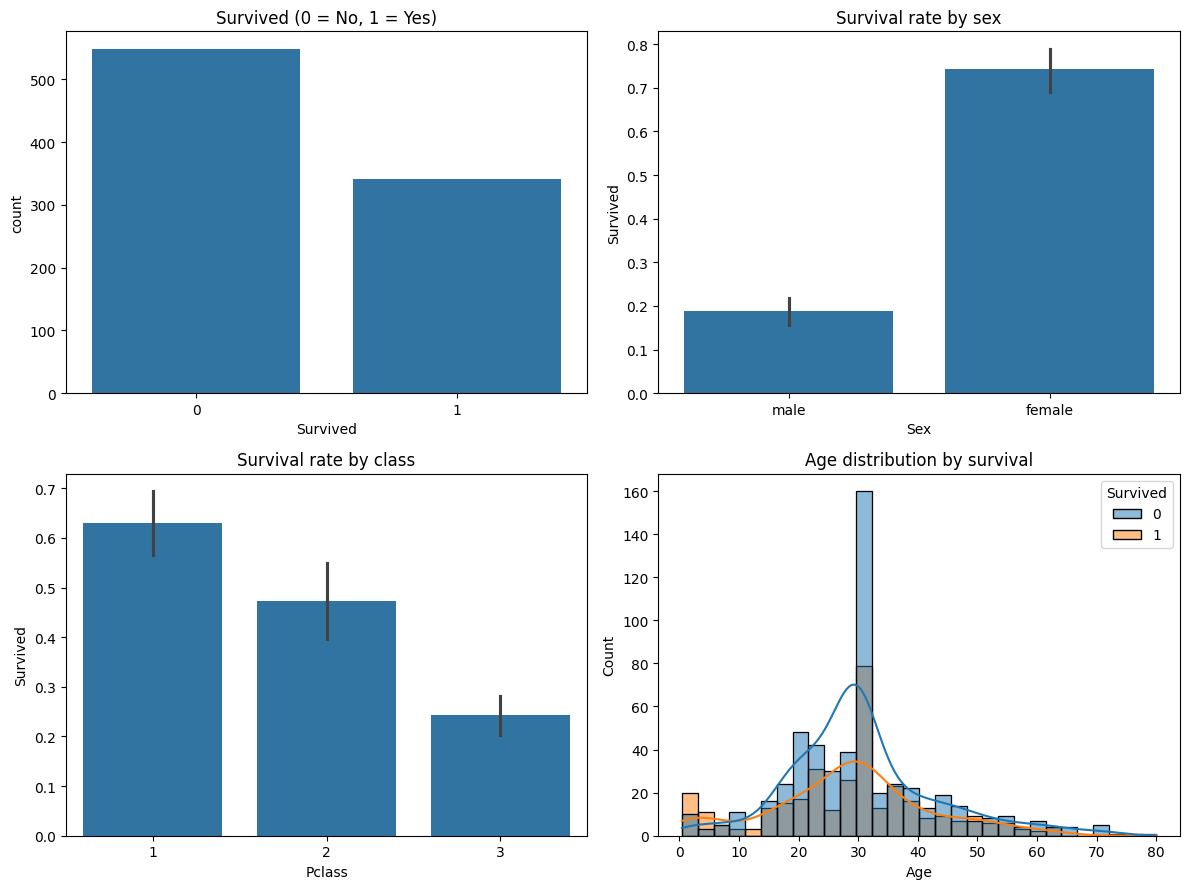

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.countplot(data=df, x='Survived', ax=axes[0,0]); axes[0,0].set_title('Survived (0 = No, 1 = Yes)')
sns.barplot(data=df, x='Sex', y='Survived', ax=axes[0,1]); axes[0,1].set_title('Survival rate by sex')
sns.barplot(data=df, x='Pclass', y='Survived', ax=axes[1,0]); axes[1,0].set_title('Survival rate by class')
sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=True, ax=axes[1,1]); axes[1,1].set_title('Age distribution by survival')
plt.tight_layout()
plt.show()

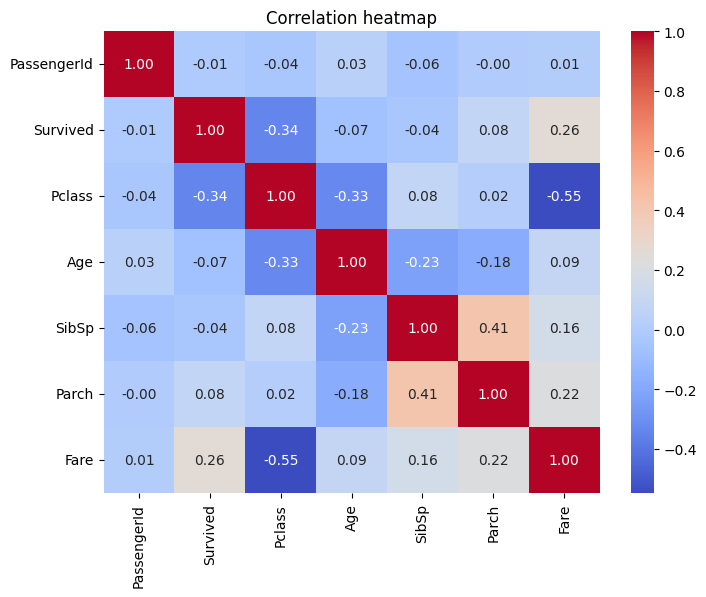

In [16]:
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()